# Einführung in das Maschinelle Lernen – Labor 1
## Explorative Datenanalyse des Ames Housing Datensatzes

Der **Ames Housing Datensatz** wurde von Dean De Cock als moderner Benchmark-Datensatz für Machine-Learning-Experimente zusammengestellt und dient als detaillierte Alternative zum klassischen Boston Housing Datensatz[cite: 2, 3]. Er dokumentiert Immobilienverkäufe in Ames, Iowa zwischen 2006 und 2010 und umfasst 2.930 Beobachtungen über 82 Variablen (Merkmale)[cite: 2].

### 1. Laden des Datensatzes
- **Dateiformat:** Die Quelldatei ist tabulatorgetrennt (`sep="\t"`), weshalb das Standard-Trennzeichen in Pandas explizit angepasst werden muss.
- **Ziel:** Einlesen der Rohdaten in ein `pandas.DataFrame` und Validierung der Dimensionen `(2930, 82)`[cite: 2].

In [2]:
from pathlib import Path
import pandas as pd

# Path to dataset
DATA_PATH = Path("../data/AmesHousing.csv")

# Load tab-separated file
df = pd.read_csv(DATA_PATH, sep="\t")

# Verify parsed dimensions
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


### 2. Erste Dateninspektion und Analyse fehlender Werte

Vor der Erstellung von Visualisierungen wird die Datenstruktur systematisch überprüft[cite: 3]:

1. **Datentypen und Speicherstruktur (`df.info()`):**
   - Identifikation von numerischen Merkmalen (z. B. Flächenmaße, Baujahre) versus kategorialen Merkmalen (z. B. Stadtviertel, Gebäudetyp)[cite: 2, 3].
2. **Statistische Kennzahlen (`df.describe()`):**
   - Überblick über zentrale Tendenzen (Mittelwert, Median) sowie Streuung (Standardabweichung, Min/Max, Quartile) zur Früherkennung extremer Werte[cite: 3].
3. **Fehlende Werte (`df.isna()`):**
   - Ermittlung von Attributen mit hohem Anteil an `NaN`-Werten[cite: 3].
   - **Wichtiger Hinweis zur Domäne:** Gemäß Datensatz-Dokumentation kodiert der Wert `NA` bei vielen Ausstattungsmerkmalen (wie `Pool QC`, `Misc Feature`, `Alley`, `Fence`, `Fireplace Qu`, `Garage Type`, `Bsmt Qual`) nicht ein tatsächliches Fehlen von Daten, sondern die Nicht-Existenz der jeweiligen Eigenschaft an der Immobilie (z. B. *kein Pool* oder *keine Garage*)[cite: 2].

In [3]:
# 1. Summary of data types and non-null counts
print("--- Dataset Info ---")
df.info()

# 2. Summary statistics for numerical features
print("\n--- Summary Statistics (Numerical) ---")
display(df.describe().T)

# 3. Check columns with highest missing value counts
print("\n--- Top 15 Columns by Missing Values ---")
missing_counts = df.isna().sum()
missing_percent = (df.isna().sum() / len(df)) * 100
missing_df = pd.DataFrame({"Missing Count": missing_counts, "Percentage (%)": missing_percent})
display(missing_df[missing_df["Missing Count"] > 0].sort_values(by="Missing Count", ascending=False).head(15))

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  Hous

,count,mean,std,min,25%,50%,75%,max
Order,2930.0,1.465500e+03,8.459625e+02,1.0,7.332500e+02,1465.5,2.197750e+03,2.930000e+03
PID,2930.0,7.144645e+08,1.887308e+08,526301100.0,5.284770e+08,535453620.0,9.071811e+08,1.007100e+09
MS SubClass,2930.0,5.738737e+01,4.263802e+01,20.0,2.000000e+01,50.0,7.000000e+01,1.900000e+02
Lot Frontage,2440.0,6.922459e+01,2.336533e+01,21.0,5.800000e+01,68.0,8.000000e+01,3.130000e+02
Lot Area,2930.0,1.014792e+04,7.880018e+03,1300.0,7.440250e+03,9436.5,1.155525e+04,2.152450e+05
Overall Qual,2930.0,6.094881e+00,1.411026e+00,1.0,5.000000e+00,6.0,7.000000e+00,1.000000e+01
Overall Cond,2930.0,5.563140e+00,1.111537e+00,1.0,5.000000e+00,5.0,6.000000e+00,9.000000e+00
Year Built,2930.0,1.971356e+03,3.024536e+01,1872.0,1.954000e+03,1973.0,2.001000e+03,2.010000e+03
Year Remod/Add,2930.0,1.984267e+03,2.086029e+01,1950.0,1.965000e+03,1993.0,2.004000e+03,2.010000e+03
Mas Vnr Area,2907.0,1.018968e+02,1.791126e+02,0.0,0.000000e+00,0.0,1.640000e+02,1.600000e+03



--- Top 15 Columns by Missing Values ---


,Missing Count,Percentage (%)
Pool QC,2917,99.556314
Misc Feature,2824,96.382253
Alley,2732,93.242321
Fence,2358,80.477816
Mas Vnr Type,1775,60.580205
Fireplace Qu,1422,48.532423
Lot Frontage,490,16.723549
Garage Qual,159,5.426621
Garage Cond,159,5.426621
Garage Yr Blt,159,5.426621


### Plot 1: Verteilung des Zielwerts (`SalePrice`)
**Fragestellung:** Wie ist der Verkaufspreis der Immobilien verteilt, und liegt eine Normalverteilung oder eine Schiefe (Skewness) vor?

- **Plot-Typ:** Histogramm mit Kernel-Density-Estimation (KDE).
- **Interpretation:**
  - Der Verkaufspreis ist deutlich **rechtsschief (right-skewed)** verteilt mit einer Häufung im Bereich von 130.000 $bis 210.000$ (Median: 160.000 $, Mittelwert: ~180.796 $).
  - Nach rechts hin existiert ein langer "Schwanz" hochpreisiger Luxusimmobilien mit Spitzenwerten von bis zu 755.000 $.
  - **Relevanz für ML (Aufgabe 2):** Lineare Modelle setzen häufig normalverteilte Zielvariablen bzw. normalverteilte Residuen voraus. Eine logarithmische Transformation (`log(SalePrice)`) ist hier für spätere Regressionsmodelle dringend zu empfehlen.

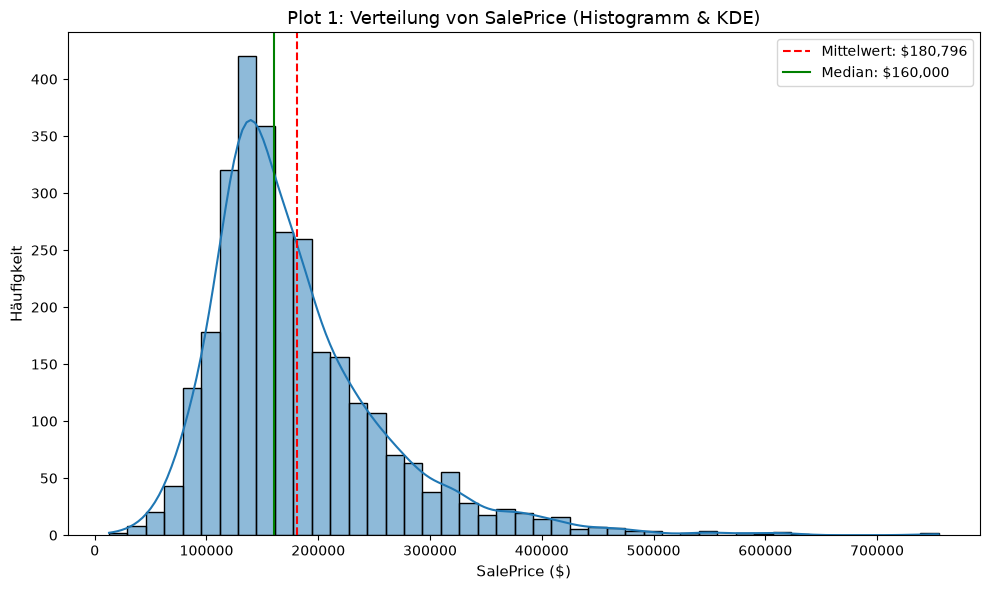

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df["SalePrice"], kde=True, bins=45, color="#1f77b4")

mean_price = df["SalePrice"].mean()
median_price = df["SalePrice"].median()

plt.axvline(
    mean_price,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Mittelwert: ${mean_price:,.0f}",
)
plt.axvline(
    median_price,
    color="green",
    linestyle="-",
    linewidth=1.5,
    label=f"Median: ${median_price:,.0f}",
)

plt.title("Plot 1: Verteilung von SalePrice (Histogramm & KDE)", fontsize=13)
plt.xlabel("SalePrice ($)", fontsize=11)
plt.ylabel("Häufigkeit", fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

### Plot 2: Oberirdische Wohnfläche vs. Verkaufspreis (`Gr Liv Area` vs `SalePrice`)
**Fragestellung:** Besteht ein linearer Zusammenhang zwischen Wohnfläche und Verkaufspreis, und lassen sich atypische Ausreißer (Outliers) identifizieren?

- **Plot-Typ:** Scatter Plot mit Hervorhebung extremer Datenpunkte.
- **Interpretation:**
  - Es besteht ein deutlicher, positiver linearer Trend: Größere Wohnfläche korreliert stark mit höheren Preisen ($r \approx 0.71$).
  - **Identifizierte Outliers:** Rechts unten sind drei auffällige Datenpunkte mit extrem großer Wohnfläche (> 4.000 sq ft), die jedoch für unter 200.000 $ verkauft wurden (z.B. Index 1498 mit 5.642 sq ft für 160.000 $). Wie von Datensatz-Autor Dean De Cock dokumentiert, handelt es sich hierbei um landwirtschaftliche/atypische Verkäufe, die vor dem Trainieren von Regressionsmodellen entfernt werden sollten.

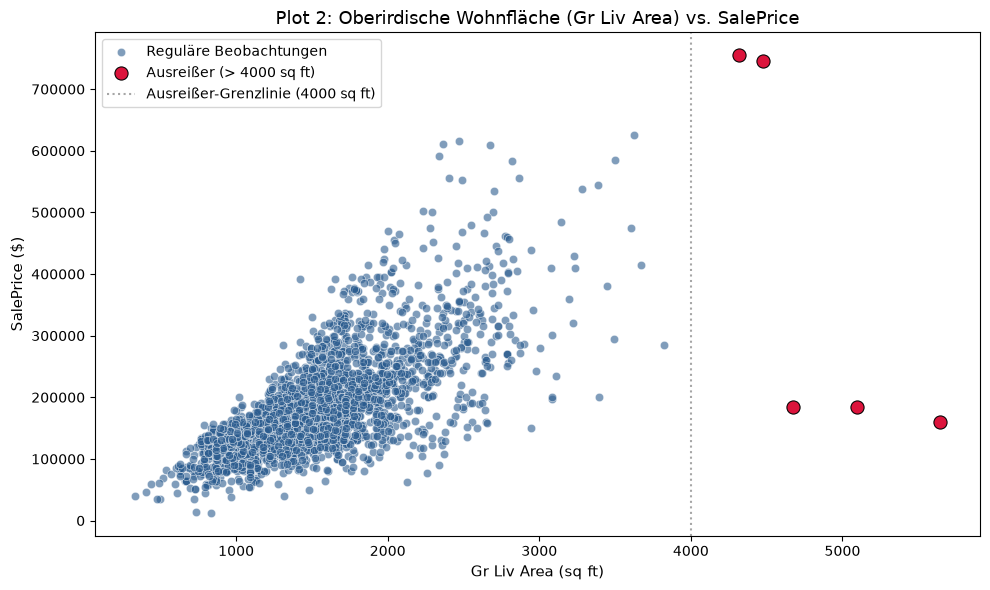

In [5]:
plt.figure(figsize=(10, 6))

# Standardpunkte
sns.scatterplot(
    data=df[df["Gr Liv Area"] <= 4000],
    x="Gr Liv Area",
    y="SalePrice",
    color="#2b5c8f",
    alpha=0.6,
    label="Reguläre Beobachtungen",
)

# Extreme Ausreißer (> 4000 sq ft)
sns.scatterplot(
    data=df[df["Gr Liv Area"] > 4000],
    x="Gr Liv Area",
    y="SalePrice",
    color="crimson",
    s=90,
    edgecolor="black",
    label="Ausreißer (> 4000 sq ft)",
)

plt.axvline(
    4000,
    color="gray",
    linestyle=":",
    alpha=0.7,
    label="Ausreißer-Grenzlinie (4000 sq ft)",
)
plt.title(
    "Plot 2: Oberirdische Wohnfläche (Gr Liv Area) vs. SalePrice", fontsize=13
)
plt.xlabel("Gr Liv Area (sq ft)", fontsize=11)
plt.ylabel("SalePrice ($)", fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

### Plot 3: Gesamtqualität vs. Verkaufspreis (`Overall Qual` vs `SalePrice`)
**Fragestellung:** Wie verhält sich die Preisspanne über die diskreten Qualitätsstufen (1 bis 10) hinweg?

- **Plot-Typ:** Box Plot mit Kennzeichnung von Median, Quartilen und Ausreißern.
- **Interpretation:**
  - `Overall Qual` weist die stärkste Korrelation mit dem Verkaufspreis auf ($r \approx 0.80$).
  - Der Anstieg verläuft exponentiell statt rein linear: Während Häuser der Stufen 1 bis 4 kaum im Preis variieren, steigen die Mediane und die Varianz ab Stufe 7 drastisch an.
  - Ab Qualitätsstufe 8 nimmt die Anzahl oberer Ausreißer stark zu, was auf Luxusanwesen mit zusätzlichen Premium-Attributen hindeutet.

C:\Users\adeli\AppData\Local\Temp\ipykernel_16980\2419755367.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


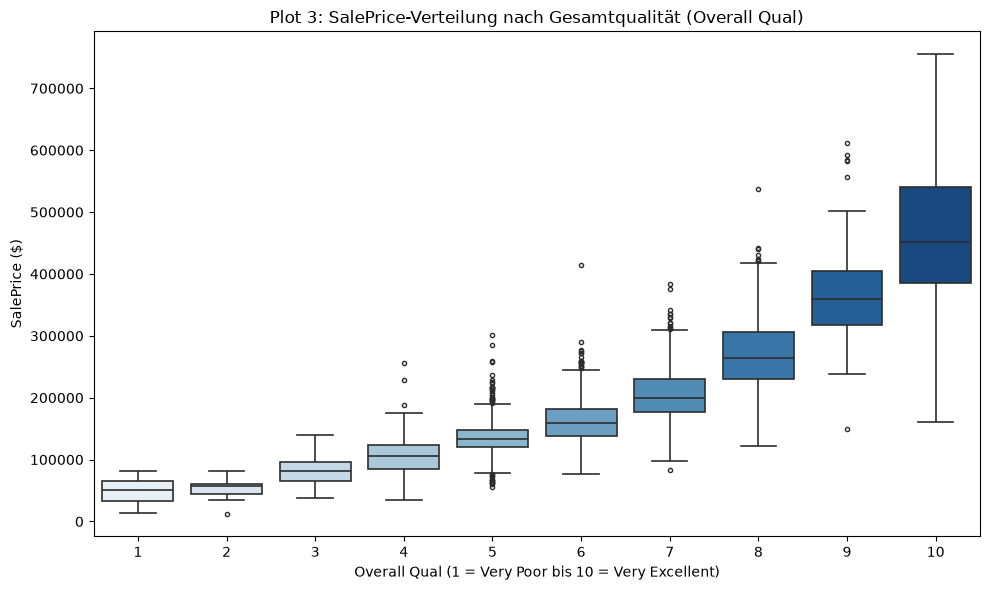

In [6]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x="Overall Qual",
    y="SalePrice",
    palette="Blues",
    fliersize=3,
    linewidth=1.2,
)

plt.title("Plot 3: SalePrice-Verteilung nach Gesamtqualität (Overall Qual)")
plt.xlabel("Overall Qual (1 = Very Poor bis 10 = Very Excellent)")
plt.ylabel("SalePrice ($)")
plt.tight_layout()
plt.show()

### Plot 4: Gebäudetyp vs. Verkaufspreis (`Bldg Type` vs `SalePrice`)
**Fragestellung:** Wie unterscheidet sich die Dichte und Streuung der Verkaufspreise zwischen Einfamilienhäusern, Reihenhäusern und Mehrfamilienhäusern?

- **Plot-Typ:** Violin Plot (Kombination aus Box Plot und Kerndichteschätzung).
- **Interpretation:**
  - **1Fam (Single-Family Detached):** Macht die Mehrheit des Datensatzes aus (über 2.400 Einträge). Zeigt die größte Streuung und deckt das gesamte Preisspektrum bis 755.000 $ ab.
  - **TwnhsE (Townhouse End Unit):** Weist im Vergleich zu mittleren Reihenhäusern (`Twnhs`) einen signifikant höheren Median und schmalere Streuung auf.
  - **Duplex & 2fmCon (Umbauten):** Häufen sich im unteren Preissegment (< 150.000 $) mit kaum vorhandenen Hochpreis-Ausreißern.

C:\Users\adeli\AppData\Local\Temp\ipykernel_16980\411035892.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


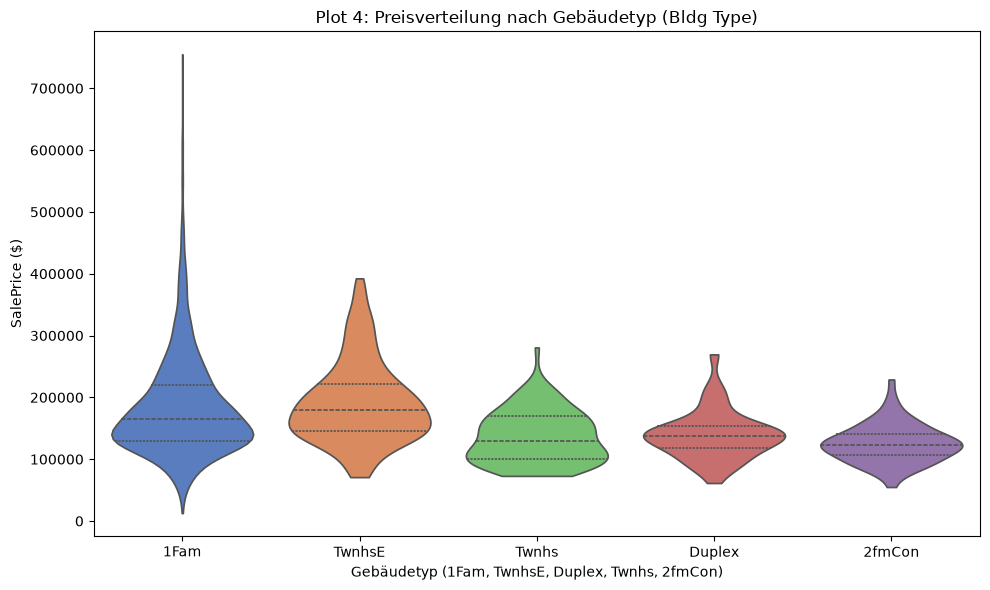

In [7]:
plt.figure(figsize=(10, 6))
sns.violinplot(
    data=df,
    x="Bldg Type",
    y="SalePrice",
    palette="muted",
    inner="quartile",
    cut=0,
)

plt.title("Plot 4: Preisverteilung nach Gebäudetyp (Bldg Type)")
plt.xlabel("Gebäudetyp (1Fam, TwnhsE, Duplex, Twnhs, 2fmCon)")
plt.ylabel("SalePrice ($)")
plt.tight_layout()
plt.show()

### Plot 5: Korrelations-Heatmap der stärksten Prädiktoren
**Fragestellung:** Welche numerischen Merkmale weisen die stärkste lineare Korrelation mit dem Verkaufspreis auf, und existiert Multikollinearität zwischen den Prädiktoren?

- **Plot-Typ:** Annotierte Korrelations-Heatmap (Top 10 korrelierte Features zu `SalePrice`).
- **Interpretation:**
  - **Stärkste Prädiktoren für `SalePrice`:**
    - `Overall Qual` ($r = 0.80$)
    - `Gr Liv Area` ($r = 0.71$)
    - `Garage Cars` ($r = 0.65$) und `Garage Area` ($r = 0.64$)
    - `Total Bsmt SF` ($r = 0.63$) und `1st Flr SF` ($r = 0.62$)
  - **Multikollinearität (Gefahr redundanter Features):**
    - `Garage Cars` und `Garage Area` sind extrem stark untereinander korreliert ($r \approx 0.89$), da sie dieselbe Information (Garagengröße) abbilden.
    - `Total Bsmt SF` und `1st Flr SF` korrelieren stark ($r \approx 0.80$), da Keller und Erdgeschoss bei typischen Haustypen dieselben Grundrisse teilen.

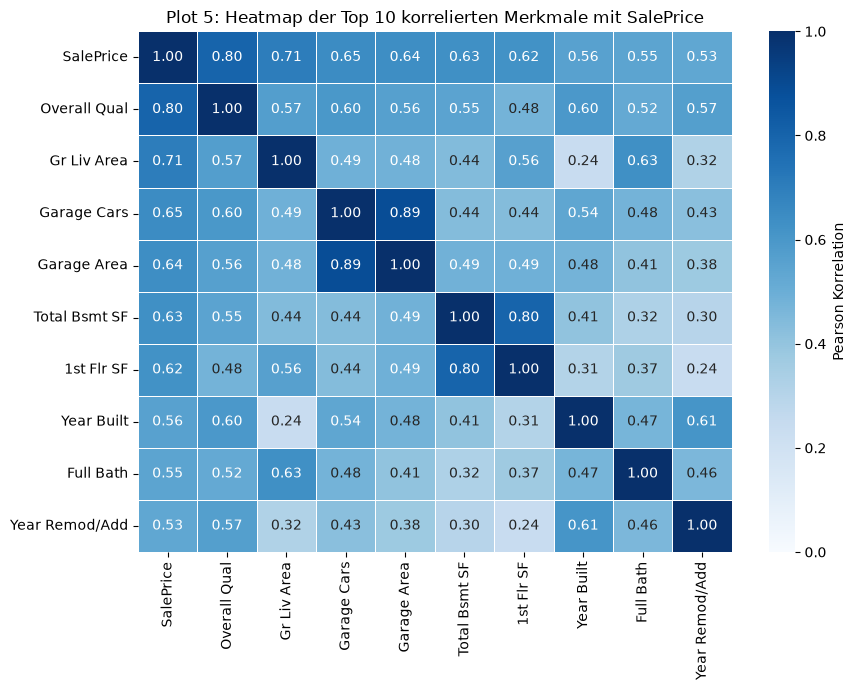

In [8]:
import numpy as np

# Top 10 numerische Features mit höchster Korrelation zu SalePrice auswählen
numeric_cols = df.select_dtypes(include=[np.number]).columns
top_corr_features = (
    df[numeric_cols].corr()["SalePrice"].abs().sort_values(ascending=False).head(10).index
)

corr_matrix = df[top_corr_features].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Korrelation"},
)

plt.title("Plot 5: Heatmap der Top 10 korrelierten Merkmale mit SalePrice")
plt.tight_layout()
plt.show()